# What we built and what it did

TabICL v2's released table stages, fine-tuned, with an image side trained from scratch on generated tables where every row also carries a real photo. The photo is encoded by frozen DINOv2 (block 4 patch tokens); the image side reads it against the 32 nearest context photos and their labels. This notebook shows one training task, walks one batch through the model, and plots the results that decided things. Numbers come from the files in `results/`.

In [1]:
import os, sys, json
os.chdir(next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.exists(os.path.join(p, "table_image_icl"))))
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt

OUT = "assets/results"
os.makedirs(OUT, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

def record(run, name):
    return json.load(open(f"results/{run}/{name}"))

GROUPED = ["PAD-UFES-20", "SoCal Houses"]            # scored with each patient or listing on one side of the split, see section 4

def benchmark(run, suffix=""):
    """The real-data records at one context size (suffix "" or "-contextN"): the benchmark's row-wise split for the
    datasets without groups, the grouped split (multabench-grouped*.json) for the two with groups."""
    m = {ds: d for ds, d in record(run, f"multabench{suffix}.json")["datasets"].items() if ds not in GROUPED}
    path = f"results/{run}/multabench-grouped{suffix}.json"
    return m | json.load(open(path))["datasets"] if os.path.exists(path) else m

## 1. One training task

A table from TabICL v2's prior. One column is hidden and shown only through the photo: its value picks the photo's class. So the photo carries information the table lost, and the model can only get it back by reading the photo.

columns kept: 7 | hidden column values: [0.81 0.7  0.68 0.71 0.65 0.79] | bins: [2 1 1 2 1 2]


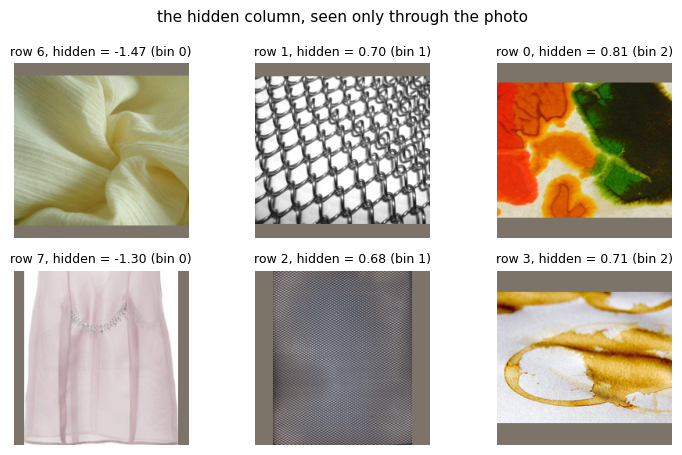

In [2]:
from table_image_icl.collections import load_collection
from table_image_icl.tasks import TaskConfig, task_batches

collections = {name: load_collection(name, max_images=600) for name in ["eurosat", "dtd"]}
cfg = TaskConfig(batch_size=2, rows=(40, 56), features=(4, 8), max_classes=4, max_bins=3, image_as_label_share=0.0)
batch = next(task_batches(cfg, collections, seed=1))
t = 0
c = collections[batch.collection[t]]
print("columns kept:", int(batch.n_columns[t]), "| hidden column values:", batch.hidden[t, :6].numpy().round(2), "| bins:", batch.bins[t, :6].numpy())

fig, axes = plt.subplots(2, 3, figsize=(7.5, 4.6))
for k in range(3):
    for i, r in enumerate(np.where(batch.bins[t].numpy() == k)[0][:2]):
        idx = int(batch.image_index[t, r])
        axes[i, k].imshow(c["images"][idx]); axes[i, k].axis("off")
        axes[i, k].set_title(f"row {r}, hidden = {batch.hidden[t, r]:.2f} (bin {k})", fontsize=9)
fig.suptitle("the hidden column, seen only through the photo", fontsize=11)
fig.tight_layout(); fig.savefig(f"{OUT}/task.png", dpi=160, bbox_inches="tight")

## 2. The model, one batch at a time

Four stages; three are TabICL v2's, pretrained on about 82M tables and fine-tuned here at a small learning rate. Column stage: each column's cells attend to each other, so a cell knows its column's distribution. Image side (ours, trained from scratch): the frozen DINOv2 patches of a row go through a small encoder, then a labelled read where they attend to the patches of the 32 nearest context photos and read their labels. Row stage: a row's cells and its patches attend to each other and are pooled into one token. In-context stage: rows attend to rows, test rows read the context labels and score the classes. The released weights are loaded from `checkpoints/block4`.

In [3]:
from table_image_icl.model import load_run
from table_image_icl.tables import contiguous_codes, prepare_table
from table_image_icl.tasks import Tasks
from table_image_icl.inputs import inputs_for

model, config = load_run("checkpoints/block4")
for name, module in model.named_children():
    print(f"{name:13s} {sum(p.numel() for p in module.parameters()) / 1e6:6.2f}M", "(TabICL v2, pretrained)" if name == "table" else "(ours)")

tasks = Tasks(cfg, collections, ["eurosat"], ["dtd"], inputs_for("dino", "cpu", block=config["dino_block"]))
inputs = tasks.inputs(batch, "cpu", "image")
n_context = inputs["y_context"].shape[1]
codes, slots = contiguous_codes(inputs["y_context"])                                # TabICL wants classes numbered 0..k-1
with torch.no_grad():
    cells = model.table.col_embedder._train_forward(prepare_table(inputs["x"], n_context), codes, None, False); print("column stage ", tuple(cells.shape))
    patches = model.photo_tokens(inputs["images"], inputs["y_context"]);                                         print("image side   ", tuple(patches.shape))
    rows = model.table.row_interactor._train_forward(torch.cat([cells, patches], 2), None);                      print("row stage    ", tuple(rows.shape))
    logits = model.table.icl_predictor._icl_predictions(rows, codes)[:, n_context:];                             print("in-context   ", tuple(logits.shape))
    log_probs = model(inputs["x"], inputs["y_context"], images=inputs["images"]);                                print("output       ", tuple(log_probs.shape), "(log-probabilities over the label slots)")
acc = (log_probs[t].argmax(-1) == batch.y_test[t]).float().mean().item()
print(f"accuracy on this task's test rows: {acc:.2f}")

table          27.55M (TabICL v2, pretrained)
embed           0.10M (ours)
encoder         0.56M (ours)
read            0.27M (ours)


Using cache found in /Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


column stage  (2, 45, 11, 128)


image side    (2, 45, 256, 128)
row stage     (2, 45, 512)
in-context    (2, 5, 10)


output        (2, 5, 10) (log-probabilities over the label slots)
accuracy on this task's test rows: 0.60


## 3. Did it learn to use the photo?

The model is scored on 400 fixed tasks whose photos come from collections it never trained on, shown four ways: the table alone, the table with each row's photo, the table with the hidden column handed back as a plain column, and the table with each row given another row's photo. Test accuracy, averaged over the tasks. The last view is a control: if the model only liked having extra tokens, it would score as well there as with the right photo.

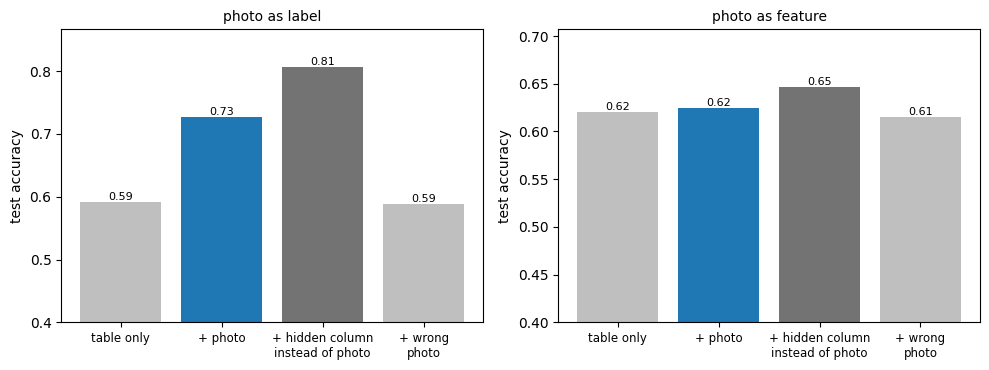

In [4]:
e = record("block4", "evaluation.json")["by_role"]
views = ["no image", "image", "column visible", "images shuffled"]
names = ["table only", "+ photo", "+ hidden column\ninstead of photo", "+ wrong\nphoto"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, role in zip(axes, ["label", "feature"]):
    acc = [e[role]["views"][v]["accuracy"] for v in views]
    bars = ax.bar(names, acc, color=["0.75", "C0", "0.45", "0.75"])
    for b, a in zip(bars, acc):
        ax.text(b.get_x() + b.get_width() / 2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"photo as {role}", fontsize=10); ax.set_ylabel("test accuracy"); ax.tick_params(axis="x", labelsize=8.5)
    ax.set_ylim(0.4, max(acc) + 0.06)
fig.tight_layout(); fig.savefig(f"{OUT}/views.png", dpi=160, bbox_inches="tight")

The photo lifts accuracy and the wrong photo does not, so the model reads the photo. A photo that stands in for the label is read well, most of the way to seeing the column itself; a photo that stands in for a feature barely helps.

## 4. Real data

MulTaBench's four validation datasets, 256 labelled rows as context, no training on the data. They are from the benchmark's extended slice: HAM10000 (dermoscopy, 7 classes), PAD-UFES-20 (smartphone lesion photo and 22 clinical features, 6 classes), SoCal Houses (listing photo and 6 features, price) and DVM-Car (car photo and 16 listing features, price). The reference is TabPFN v2 fed the table plus a PCA of frozen DINOv2 features: the same photo information, a strong table learner.

**The split.** MulTaBench splits rows i.i.d. and says its splits are not audited for group structure. Read off the benchmark's own files, two of the four datasets have groups: PAD-UFES-20 rows are lesions of 1,240 patients (32% of test rows have another lesion of the same patient among the training rows, with the same clinical features and, 59% of the time, the same diagnosis), and SoCal Houses lists the same house more than once (26% of test rows have a twin with the identical price among the training rows). HAM10000 has one image per lesion and DVM-Car one photo per advert. For the two grouped datasets every number in this notebook comes from a split that keeps each patient or listing on one side (`scripts/benchmark.py --grouped`, records `multabench-grouped*.json`); the benchmark's row-wise records are kept next to them. At 256 context rows the two splits agree within noise (PAD-UFES-20 0.929 row-wise, 0.933 grouped); the difference shows at 10,000 rows, section 6.

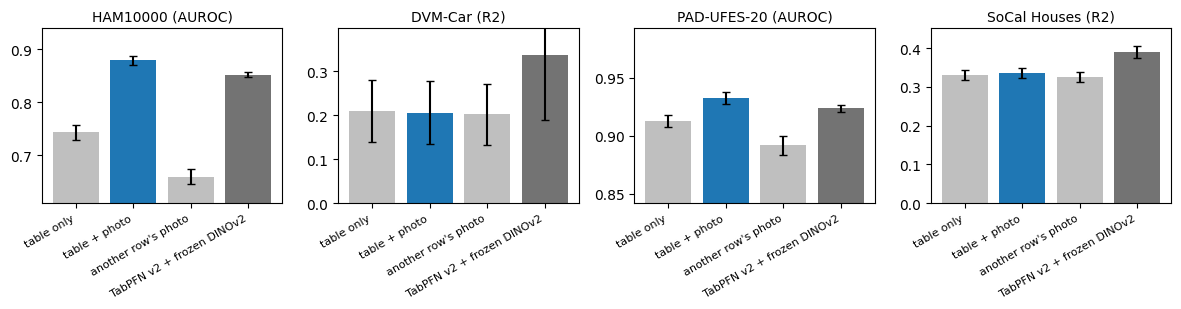

In [5]:
m = benchmark("block4")
keys = ["ours, table only", "ours, table + image", "ours, image of another row", "TabPFN v2, table + frozen DINOv2 PCA"]
names = ["table only", "table + photo", "another row's photo", "TabPFN v2 + frozen DINOv2"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (ds, d) in zip(axes, m.items()):
    means = [d[k]["mean"] for k in keys]; ses = [d[k]["se"] for k in keys]
    ax.bar(range(4), means, yerr=ses, color=["0.75", "C0", "0.75", "0.45"], capsize=3)
    ax.set_xticks(range(4)); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_title(f"{ds} ({d['metric']})", fontsize=10)
    lo = min(means) - 0.05 if d["metric"] == "AUROC" else min(0, min(means) - 0.05)
    ax.set_ylim(lo, max(means) + 0.06)
fig.tight_layout(); fig.savefig(f"{OUT}/realdata.png", dpi=160, bbox_inches="tight")

On HAM10000 the photo adds 0.14 AUROC and on PAD-UFES-20 0.02, with no training on the data, and the model is ahead of the frozen-feature reference on both. On the two regression sets the reference is ahead with or without the photo, and on DVM-Car the photo adds nothing for either method at 256 context rows; its R² also swings between splits because prices are heavy-tailed.

## 5. The ablation that mattered: which DINOv2 block

Every arm shares the table side (TabICL v2's stages, learning rate 1e-5) and the image-side setting (top-k 32 reads, 25k steps, seed 0). Only what the image side receives differs: frozen DINOv2 patch tokens from block 4, 8 or 12, DINOv2's final CLS and register tokens, or raw pixels through one linear layer trained from scratch (grey).

Deeper, more semantic DINOv2 features win on generated tasks and lose on the real data; the ordering on the medical sets is the reverse of the ordering on generated photos. The from-scratch arm is the extreme case: the weakest on generated tasks and the best on HAM10000, level with block 4 on the other three. The reference lines on the real-data panels are TabPFN v2 on the table alone (dashed) and TabPFN v2 on the table plus 30 PCA components of frozen DINOv2 final features (dotted), both at the same 256 context rows.

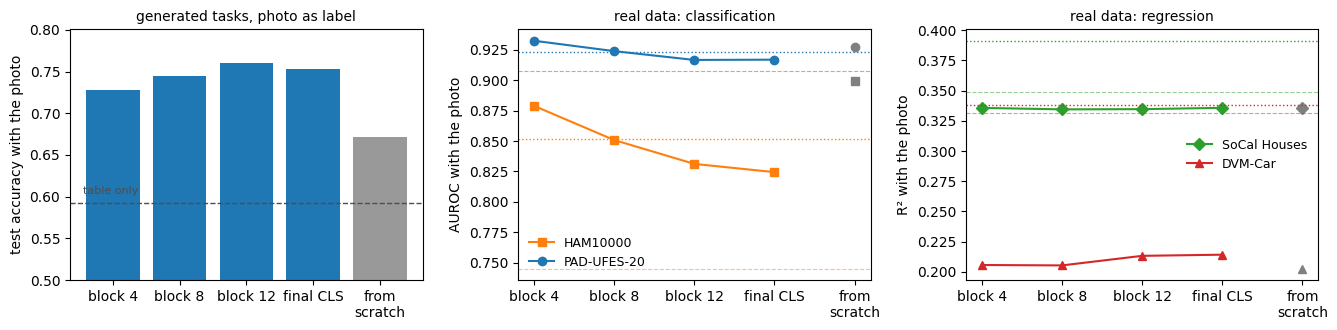

In [6]:
arms = {"block 4": "block4", "block 8": "block8", "block 12": "block12", "final CLS": "cls"}
scratch = {"from\nscratch": "pixels"}
KEY = "ours, table + image"
def scores(runs):
    photo = [record(r, "evaluation.json")["by_role"]["label"]["views"]["image"]["accuracy"] for r in runs.values()]
    real = {ds: [benchmark(r)[ds][KEY]["mean"] for r in runs.values()] for ds in ["HAM10000", "PAD-UFES-20", "SoCal Houses", "DVM-Car"]}
    return photo, real
with_photo, real = scores(arms)
scratch_photo, scratch_real = scores(scratch)
table_only = np.mean([record(r, "evaluation.json")["by_role"]["label"]["views"]["no image"]["accuracy"] for r in (arms | scratch).values()])
ref = benchmark("block4")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4))
axes[0].bar(list(arms), with_photo, color="C0"); axes[0].bar(list(scratch), scratch_photo, color="0.6")
axes[0].axhline(table_only, color="0.3", ls="--", lw=1); axes[0].text(-0.45, table_only + 0.01, "table only", fontsize=8, ha="left", color="0.3")
axes[0].set_ylim(0.5, max(with_photo) + 0.04); axes[0].set_ylabel("test accuracy with the photo"); axes[0].set_title("generated tasks, photo as label", fontsize=10)
for ds, mk, c in [("HAM10000", "s", "C1"), ("PAD-UFES-20", "o", "C0")]:
    axes[1].plot(list(arms), real[ds], mk + "-", color=c, label=ds); axes[1].plot(list(scratch), scratch_real[ds], mk, color="0.5")
    axes[1].axhline(ref[ds]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color=c, ls=":", lw=1); axes[1].axhline(ref[ds]["TabPFN v2, table only"]["mean"], color=c, ls="--", lw=0.8, alpha=0.5)
axes[1].set_ylabel("AUROC with the photo"); axes[1].legend(frameon=False, fontsize=9); axes[1].set_title("real data: classification", fontsize=10)
for ds, mk, c in [("SoCal Houses", "D", "C2"), ("DVM-Car", "^", "C3")]:
    axes[2].plot(list(arms), real[ds], mk + "-", color=c, label=ds); axes[2].plot(list(scratch), scratch_real[ds], mk, color="0.5")
    axes[2].axhline(ref[ds]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color=c, ls=":", lw=1); axes[2].axhline(ref[ds]["TabPFN v2, table only"]["mean"], color=c, ls="--", lw=0.8, alpha=0.5)
axes[2].set_ylabel("R² with the photo"); axes[2].legend(frameon=False, fontsize=9); axes[2].set_title("real data: regression", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/depth.png", dpi=160, bbox_inches="tight")

## 6. More context rows, no retraining

The model was trained on tables of 64 to 256 rows. Scoring it with more context rows costs nothing but inference: the source cap of the labelled read is raised to match, and the in-context stage extrapolates. The frozen reference gets the same rows each time. MulTaBench caps the training side of a split at 10,000 rows and most datasets have fewer, so each line stops where its data stops (HAM10000 at 4,980 rows, PAD-UFES-20 at 1,094). The lines are the model with frozen block-4 tokens, with and without the photo, and the from-scratch arm with the photo.

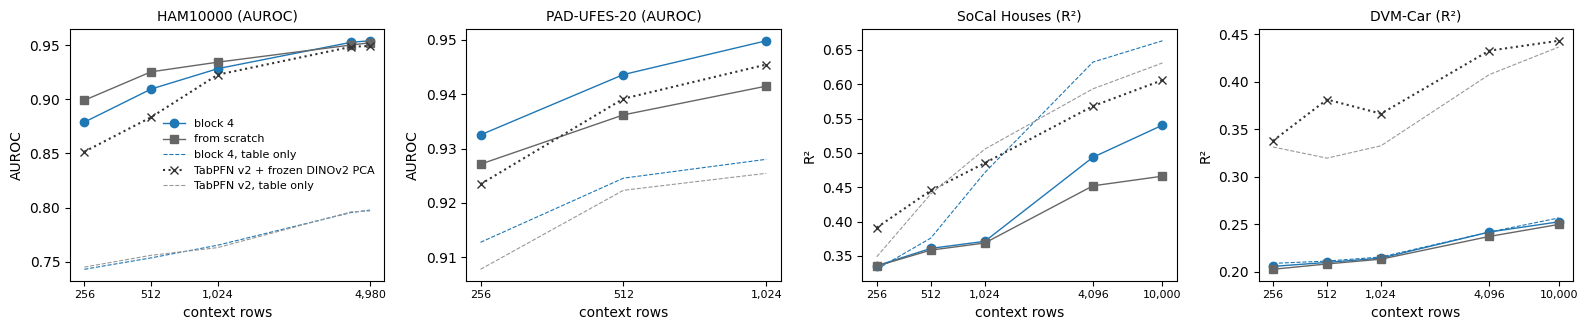

In [7]:
lines = {"block 4": ("block4", "C0", "o", KEY), "from scratch": ("pixels", "0.4", "s", KEY), "block 4, table only": ("block4", "C0", "", "ours, table only")}
SIZES = [256, 512, 1024, 4096, 10000]
def sweep(run, ds, key=KEY):
    points = {}
    for n in SIZES:
        suffix = "" if n == 256 else f"-context{n}"
        d = benchmark(run, suffix).get(ds) if os.path.exists(f"results/{run}/multabench{suffix}.json") else None
        if d is not None:                                        # a grouped dataset has no point where its grouped record stops
            points[d["context_rows"]] = d[key]["mean"]
    return sorted(points.items())
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, ds in zip(axes, ["HAM10000", "PAD-UFES-20", "SoCal Houses", "DVM-Car"]):
    for name, (run, color, mk, key) in lines.items():
        pts = sweep(run, ds, key)
        ax.plot(*zip(*pts), mk + ("-" if mk else "--"), color=color, lw=1 if mk else 0.8, label=name)
    pts = sweep("block4", ds, "TabPFN v2, table + frozen DINOv2 PCA"); ax.plot(*zip(*pts), "x:", color="0.2", label="TabPFN v2 + frozen DINOv2 PCA")
    pts = sweep("block4", ds, "TabPFN v2, table only"); ax.plot(*zip(*pts), "--", color="0.6", lw=0.8, label="TabPFN v2, table only")
    metric = benchmark("block4")[ds]["metric"].replace("R2", "R²")
    ax.set_xscale("log"); ax.set_xlabel("context rows"); ax.set_title(f"{ds} ({metric})", fontsize=10); ax.set_ylabel(metric)
    shown = sorted({x for run, _, _, _ in lines.values() for x, _ in sweep(run, ds)}); shown = [x for i, x in enumerate(shown) if i == len(shown) - 1 or shown[i + 1] > 1.3 * x]; ax.set_xticks(shown); ax.set_xticklabels([f"{x:,}" for x in shown], fontsize=8); ax.minorticks_off()
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/context.png", dpi=160, bbox_inches="tight")

On the two classification sets both arms extrapolate to 4 to 20 times their training context and keep improving; the lead over the frozen reference is largest at 256 to 1,024 rows and the methods meet at the largest contexts, where the table-only view and TabPFN v2 meet too. The regression sets tell a different story. On SoCal Houses the table-only view keeps improving to 0.66 R² at 10,000 rows, above TabPFN v2, but the photo starts to cost from about 1,000 rows on and costs 0.12 at the end; the frozen reference loses from its PCA columns there as well. This is with the listing twins kept on one side of the split; on the benchmark's row-wise split every table-only number is higher at large context (0.72 for us at 10,000 rows), because a learner that finds a test row's twin in the context gets the price exactly, and the photo's cost looks the same. On DVM-Car the photo never matters and the table-only view trails TabPFN v2 by 0.18 at every size. The photo's advantage for in-context reading is a few-shot advantage, and on regression the image side is a liability once the table has enough rows.

## 7. The five arms, in one table

The numbers behind section 5. Test accuracy on the 400 generated tasks with the photo (and, for reference, without it), then the four validation sets with the photo.

In [8]:
rows = []
for name, r in (arms | scratch).items():
    e = record(r, "evaluation.json")["by_role"]; m = benchmark(r)
    rows.append([name.replace("\n", " "), round(e["label"]["views"]["no image"]["accuracy"], 3), round(e["label"]["views"]["image"]["accuracy"], 3),
                 round(e["feature"]["views"]["image"]["accuracy"], 3)] + [round(m[ds][KEY]["mean"], 3) for ds in ["HAM10000", "PAD-UFES-20", "SoCal Houses", "DVM-Car"]])
pd.DataFrame(rows, columns=["arm", "table only", "with photo (as label)", "with photo (as feature)", "HAM AUROC", "PAD AUROC", "SoCal R²", "DVM-Car R²"]).set_index("arm")

,table only,with photo (as label),with photo (as feature),HAM AUROC,PAD AUROC,SoCal R²,DVM-Car R²
arm,,,,,,,
block 4,0.591,0.728,0.624,0.879,0.933,0.336,0.206
block 8,0.591,0.745,0.632,0.851,0.924,0.335,0.205
block 12,0.594,0.761,0.631,0.831,0.917,0.335,0.213
final CLS,0.593,0.753,0.635,0.824,0.917,0.336,0.214
from scratch,0.595,0.672,0.621,0.899,0.927,0.335,0.203


What we take from this: the model learns to read a photo in context, on HAM10000 and PAD-UFES-20 it is ahead of frozen features plus TabPFN v2 at 256 context rows, and real-data numbers are the ones to trust, since gains on generated tasks (deeper blocks) did not carry over. The in-context stage inherited from TabICL v2 is what lets the model use far more context rows than it was trained on.